# Tutorial 6: Aligning spatial transcriptomics data to H&E image of human breast cancer data from Xenium 

## Data Preparation

Please download the required data files from the provided link:
[Download here](https://pan.baidu.com/s/17K1cmxOPmhSvV6dG6gnafw?pwd=sjbx)

- `rep1.h5ad`
- `rep2_HE.png`

After downloading, place both files into the `datasets` folder located in the same directory as this notebook.

The folder structure should be organized as follows:

```
project_root/
│
├── datasets/
│   └── HBC/
│       ├── rep1.h5ad
│       └── rep2_HE.png
│
├── Tutorial6_Aligning_spatial_transcriptomics_data_to_H&E_image_of_human_breast_cancer_data_from_Xenium.ipynb
│
└── SpaMOMA/
```

## import packages

In [1]:
from SpaMOMA.SpaMOMA import SpaMOMA

site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


2026-11-22 22:41:23.687726: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-22 22:41:23.735245: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-22 22:41:23.735297: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-22 22:41:23.735333: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-22 22:41:23.746013: I tensorflow/core/platform/cpu_feature_g

2026-11-22 22:41:26.256314: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


## Specify Slice Metadata

In [2]:
save_directory = "./SpaMOMA_output/HBC/"  
spamoma = SpaMOMA(save_dir=save_directory)
spamoma.add_slice(
    sample_id="rep1",  
    raw_data_path="./datasets/HBC/rep1.h5ad",  
    feature="rna"  
)
spamoma.add_slice(
    sample_id="rep2_HE",  
    raw_data_path="./datasets/HBC/rep2_HE.png",  
    feature="img"  
)
spamoma.set_reference('rep2_HE')

In [3]:
print(f"aligning {[sid for sid in spamoma.input_slice_dict.keys() if sid != spamoma.reference_sample_id]} to {spamoma.reference_sample_id}")

aligning ['rep1'] to rep2_HE


## Data Preprocessing

preprocessing rna features...


------Calculating spatial graph...


The graph contains 1148000 edges, 164000 cells.
7.0000 neighbors per cell on average.


Size of Input:  (164000, 313)


2026-11-22 21:57:37.659404: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1886] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 79193 MB memory:  -> device: 0, name: NVIDIA A100 80GB PCIe, pci bus id: 0000:ca:00.0, compute capability: 8.0
2026-11-22 21:57:37.663749: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:382] MLIR V1 optimization pass is not enabled


2026-11-22 21:57:38.243793: I tensorflow/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


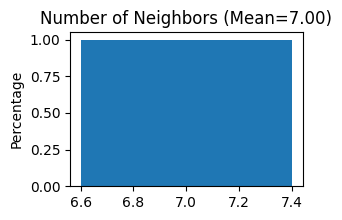

In [4]:
spamoma.preprocess_input_slices({
    'rep2_HE':{
        'downsample':False
    }
})

## Generate Spatial Pattern Images

generating spatial pattern image... gaussian_sigma:0.8, interpolation_method:linear, max_distance_ratio"1.2


saving image...


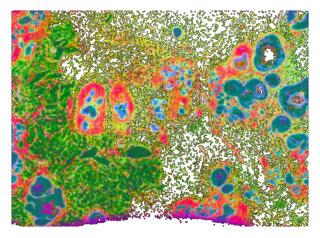

Img for rep1 is saved to ./SpaMOMA_output/HBC/rep1/RGB.png


Original image saved to: ./SpaMOMA_output/HBC/rep2_HE/RGB.png


In [5]:
spamoma.generate_imgs({
    'rep1':{
        'gaussian_sigma':0.8,
        'max_distance_ratio':1.2, 
    }
})

In [6]:
spamoma.input_slice_dict

{'rep1': {'sample_id': 'rep1',
  'raw_data_path': './datasets/HBC/rep1.h5ad',
  'feature': 'rna',
  'pseudo_color_key': 'pca',
  'processed_data': AnnData object with n_obs × n_vars = 164000 × 313
      obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'n_counts', 'image_col', 'image_row', 'spot', 'img_x', 'img_y', 'spot_x', 'spot_y', 'batch', 'my_pixel_x', 'my_pixel_y'
      var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
      uns: 'log1p', 'hvg', 'spatial_neighbors', 'moranI'
      obsm: 'he', 'image_coor', 'spatial', 'pca'
      layers: 'raw'
      obsp: 'spatial_connectivities', 'spatial_distances',
  'SPI_path': './SpaMOMA_output/HBC/rep1/RGB.png'},
 'rep2_HE': {'sample_id': 'rep2_HE',
  'raw_data_path': './datasets/HBC/rep2_HE.png',
  'feature': 'img',
  'SPI_path': './SpaMOMA_output/HBC/rep2_HE/RGB.png'

## Model Training

In [7]:
spamoma.train(coarse_epochs=100, fine_epochs=120)

{'status': 'completed',
 'run_id': '20261122-220346-4a843932',
 'run_dir': './SpaMOMA_output/HBC/runs/20261122-220346-4a843932',
 'execution_mode': 'sequential',
 'stages': {'coarse': {'best_path': './SpaMOMA_output/HBC/runs/20261122-220346-4a843932/coarse_model/best.pth',
   'last_path': './SpaMOMA_output/HBC/runs/20261122-220346-4a843932/coarse_model/last.pth',
   'resume_path': './SpaMOMA_output/HBC/runs/20261122-220346-4a843932/coarse_model/resume.pt',
   'history_path': './SpaMOMA_output/HBC/runs/20261122-220346-4a843932/coarse_model/history.jsonl',
   'global_step': 330,
   'best_metric': 1.2869566821288243,
   'best_epoch': 100,
   'optimizer_steps': 330,
   'attempted_steps': 330,
   'skipped_updates': 0,
   'selected_pretrained': False,
   'baseline_preservation': {'epe_px': 6.2989248306148315,
    'pck_1px': 0.7070398769943489,
    'pck_3px': 0.8515071187523713,
    'valid_fraction': 0.798453443877551,
    'metric_scope': 'held_out_synthetic_transforms',
    'white_augmentati

## Slice Alignment

coarse checkpoint: ./SpaMOMA_output/HBC/runs/20261122-220346-4a843932/coarse_model/last.pth


fine checkpoint: ./SpaMOMA_output/HBC/runs/20261122-220346-4a843932/fine_model/last.pth


rep2_HE image saved to: ./SpaMOMA_output/HBC//alignment_output/rep2_HE.png


****************** aligning rep1 to rep2_HE ..... ******************
Loading RoMa: ./SpaMOMA_output/HBC/runs/20261122-220346-4a843932/coarse_model/last.pth; DINO: check_points/dinov2_vitl14_pretrain.pth; resolution: (560, 560)


Loading RoMa: ./SpaMOMA_output/HBC/runs/20261122-220346-4a843932/fine_model/last.pth; DINO: check_points/dinov2_vitl14_pretrain.pth; resolution: (560, 560)


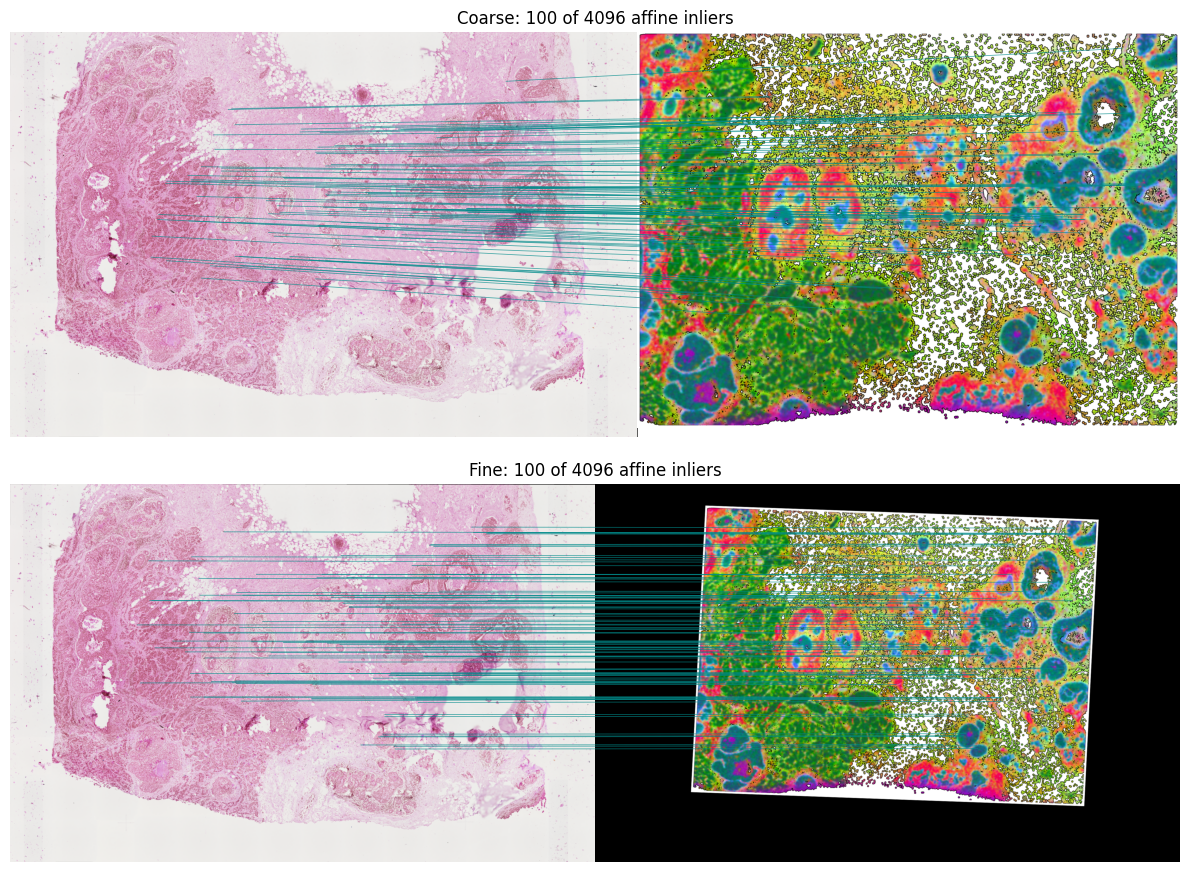

aligned rep1 adata is saved to: ./SpaMOMA_output/HBC//alignment_output/rep1.h5ad
fine alignment done!


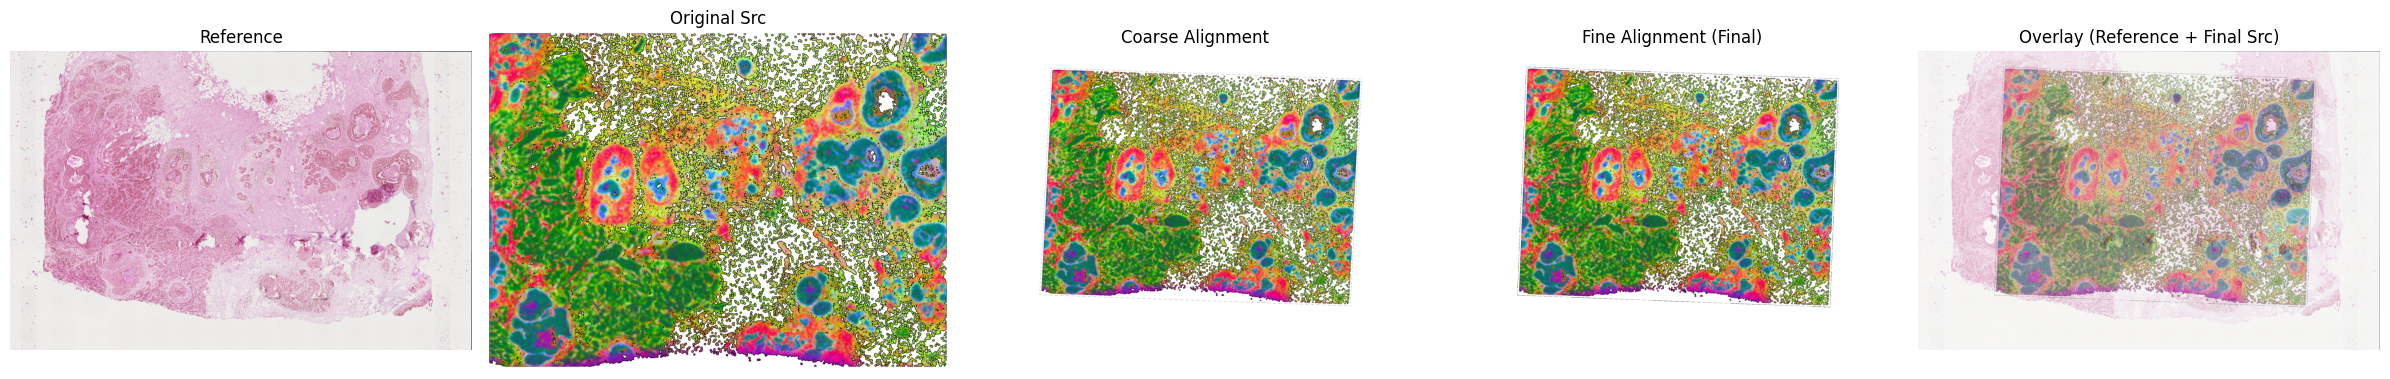

In [8]:
spamoma.align_slices(visualize_correspondences=True)

## Visualize Alignment Results

Overlaying aligned slice for sample: rep1


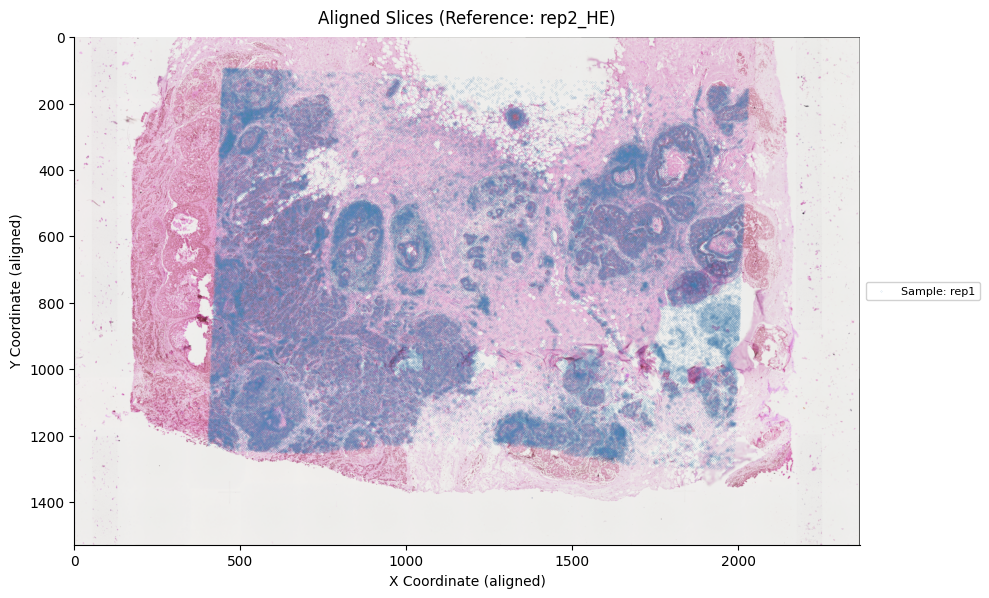

In [9]:
spamoma.visualize_aligned_slices(figsize=(10,10),point_size=0.01)